# Missingness

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

In [2]:
from src.data import load_ett, chronological_split, scale

train, test = chronological_split(load_ett())
df, _, _ = scale(train=train, test=test)

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.missingness import simulate_missingness
from src.figures_cfg import apply_theme

apply_theme()

In [4]:
mechanisms = ["mar", "mcar", "mnar"]
proportions = [10, 30, 50]

---

## Proportions

In [5]:
proportion_dict = {}

for mech in mechanisms:

    proportion_dict[mech] = {}

    for prop in proportions:

        X, _ = simulate_missingness(df=df, mechanism=mech, n=prop, random_seed=1)

        proportion_dict[mech][prop] = X.isna().sum().sum() / df.size

proportion_results = pd.DataFrame(proportion_dict)

True proportions (with seed 1) for each mechanism.

In [6]:
proportion_results

,mar,mcar,mnar
10,0.099991,0.099991,0.099991
30,0.299995,0.299995,0.299995
50,0.500000,0.500000,0.500000


Exactly the same number within each proportion, error only due to rounding.

## Distributions

### Compare distributions of masked and true values

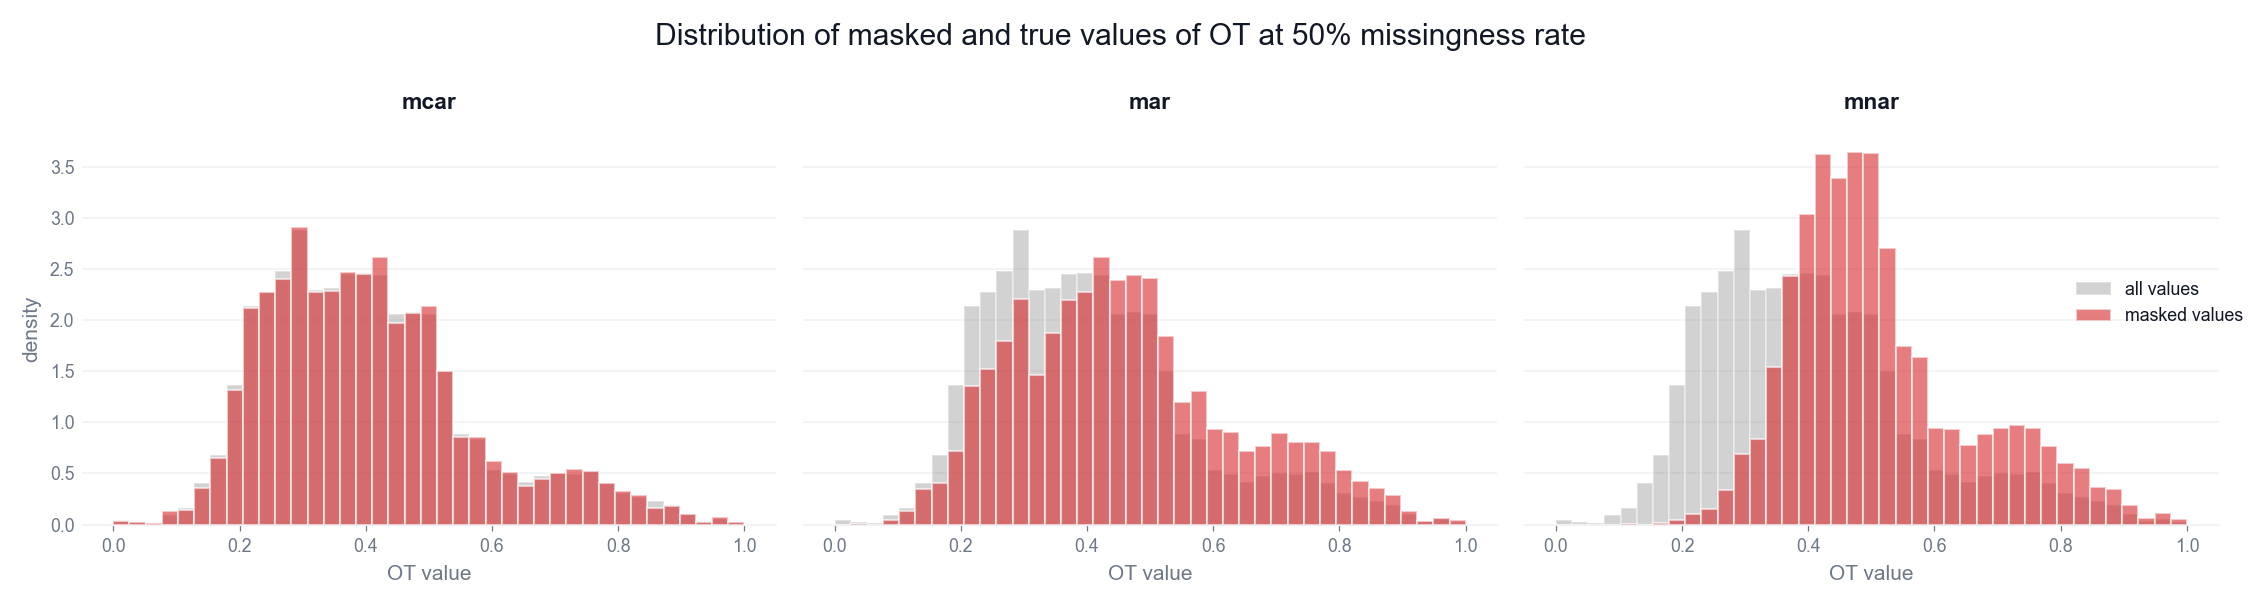

In [28]:
TARGET = "OT"
PROPORTION = 50
SEED = 1

full = df[TARGET]
bins = np.linspace(full.min(), full.max(), 40)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, mech in zip(axes, mechanisms):
    gappy, mask = simulate_missingness(df, mech, PROPORTION, SEED)
    mask_col = mask[TARGET]
    masked_true_vals = full[mask_col]

    ax.hist(full, bins=bins, density=True, alpha=0.35,
            color="grey", label="all values")
    ax.hist(masked_true_vals, bins=bins, density=True, alpha=0.6,
            color="tab:red", label="masked values")
    ax.set_title(mech)
    ax.set_xlabel(f"{TARGET} value")

axes[0].set_ylabel("density")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center right")
plt.suptitle("Distribution of masked and true values of OT at 50% missingness rate")
plt.tight_layout()
plt.show()

MCAR preserves distribution.

MAR

In [20]:
df.columns

Index(['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT'], dtype='str')

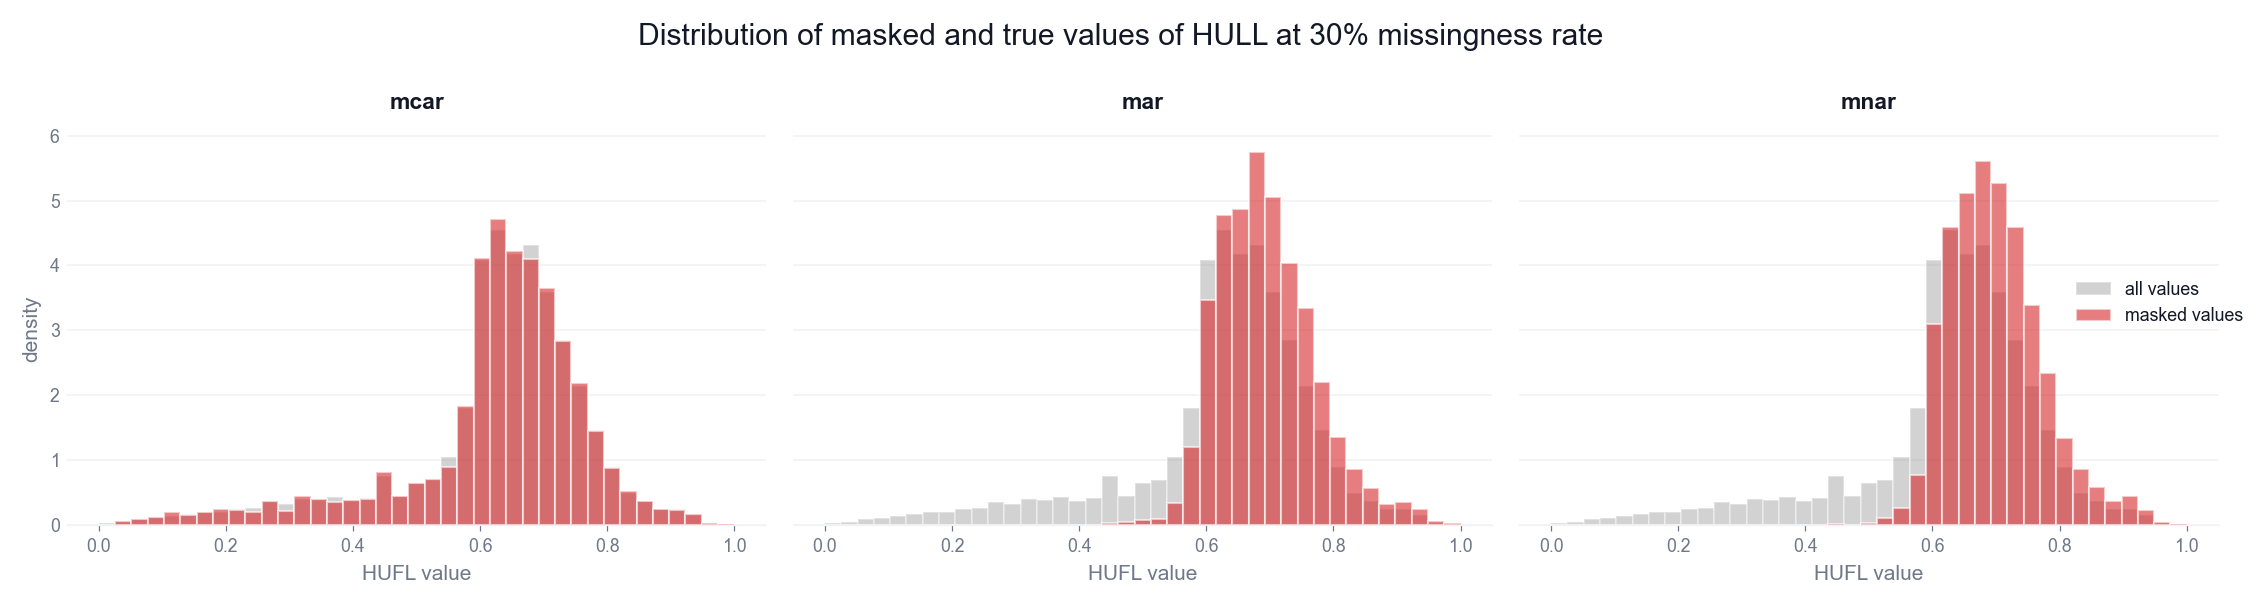

In [26]:
TARGET = "HUFL"
PROPORTION = 30
SEED = 1

full = df[TARGET]
bins = np.linspace(full.min(), full.max(), 40)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, mech in zip(axes, mechanisms):
    gappy, mask = simulate_missingness(df, mech, PROPORTION, SEED)
    mask_col = mask[TARGET]
    masked_true_vals = full[mask_col]

    ax.hist(full, bins=bins, density=True, alpha=0.35,
            color="grey", label="all values")
    ax.hist(masked_true_vals, bins=bins, density=True, alpha=0.6,
            color="tab:red", label="masked values")
    ax.set_title(mech)
    ax.set_xlabel(f"{TARGET} value")

axes[0].set_ylabel("density")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center right")
plt.suptitle("Distribution of masked and true values of HULL at 30% missingness rate")
plt.tight_layout()
plt.show()

### Compare distributions of MAR with driver column

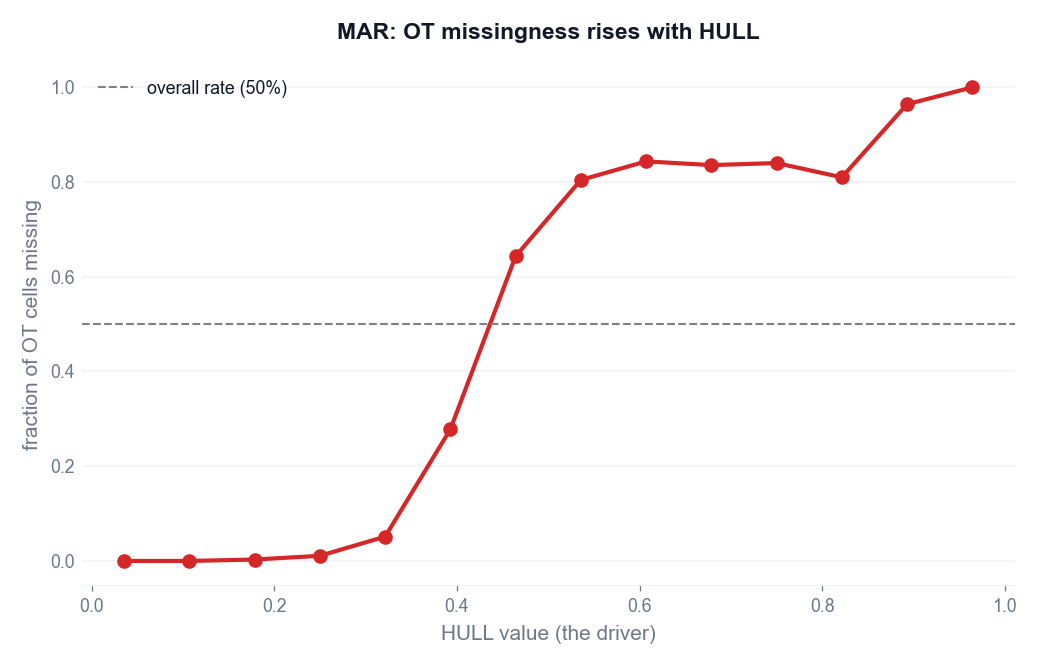

In [33]:
import numpy as np
import matplotlib.pyplot as plt

driver = df.corr()["OT"].drop("OT").abs().idxmax()
gappy, mask = simulate_missingness(df, "mar", 50, 1)

driver_vals = df[driver].to_numpy()
ot_missing = mask["OT"].to_numpy().astype(float)

bins = np.linspace(driver_vals.min(), driver_vals.max(), 15)
idx = np.digitize(driver_vals, bins)
rate = [ot_missing[idx == b].mean() for b in range(1, len(bins))]
centers = (bins[:-1] + bins[1:]) / 2

plt.figure(figsize=(7, 4.5))
plt.plot(centers, rate, "o-", color="tab:red")
plt.axhline(0.5, color="grey", ls="--", lw=1, label="overall rate (50%)")
plt.xlabel(f"{driver} value (the driver)")
plt.ylabel("fraction of OT cells missing")
plt.title(f"MAR: OT missingness rises with {driver}")
plt.legend(); plt.tight_layout(); plt.show()

C:\Users\stuwi\AppData\Local\Temp\ipykernel_19944\3889088371.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([observed, missing], labels=["OT observed", "OT missing"])


Text(0.5, 1.0, 'MAR: driver value by OT missingness')

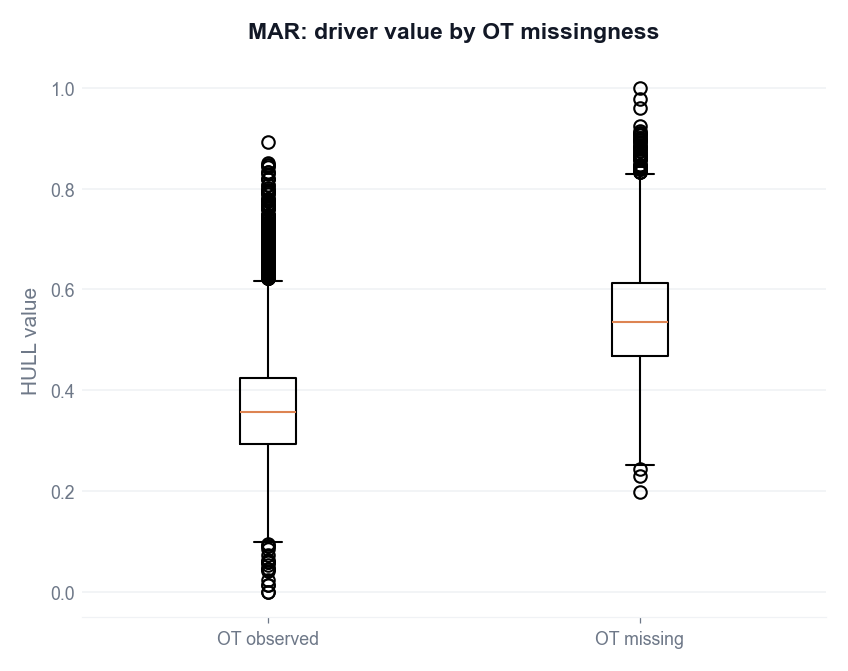

In [34]:
observed = df[driver][~mask["OT"]]
missing  = df[driver][mask["OT"]]
plt.boxplot([observed, missing], labels=["OT observed", "OT missing"])
plt.ylabel(f"{driver} value"); plt.title("MAR: driver value by OT missingness")